# Import required libraries. The energies will be computed using PySCF, library for computational chemistry. It only runs on Mac, Linux, and Linux subsystems for Windows (e.g. Ubuntu). 

In [1]:
from pyscf import gto
import numpy as np
import time

In [159]:
# r_list is a list of all of the bond lengths at which we want to obtain the ground state energy
r_list = np.arange(0.7, 4.1, 0.1)
# r_list = np.arange(1.25, 1.6+0.05, 0.05)

potential_energy_list = [] # This will hold the results

# For each bond length, we will compute the ground state energy
for r in r_list:
    
    mol = gto.Mole()
    mol.atom = f'''H  0 0 0; H {r} 0 0''' # We create the molecule by specifying the atoms and their coordinates (x,y,z)
    mol.basis = 'sto-3g' # This is the basis set in which the schrodinger equation will be solved
    mol.unit = 'bohr' # The units for the result
    mol.build() # This builds the molecule
    
    # The following code applies density functional theory to calculate the ground state energy
    mf = mol.KS()
    mf.xc = 'b3lyp'
    potential_energy_list.append(mf.kernel())

    # Orbital energies, Mulliken population etc.
    mf.analyze()

converged SCF energy = -0.879855229346926
**** MO energy ****
MO #1   energy= -0.575053036826154 occ= 2
MO #2   energy= 0.950637141420438  occ= 0
 ** Mulliken atomic charges  **
charge of    0H =     -0.00000
charge of    1H =     -0.00000
Dipole moment(X, Y, Z, Debye): -0.00000,  0.00000,  0.00000
converged SCF energy = -0.990101107398496
**** MO energy ****
MO #1   energy= -0.547709811318896 occ= 2
MO #2   energy= 0.852890153866128  occ= 0
 ** Mulliken atomic charges  **
charge of    0H =      0.00000
charge of    1H =     -0.00000
Dipole moment(X, Y, Z, Debye): -0.00000,  0.00000,  0.00000
converged SCF energy = -1.06261351204642
**** MO energy ****
MO #1   energy= -0.521757940253587 occ= 2
MO #2   energy= 0.762556128182481  occ= 0
 ** Mulliken atomic charges  **
charge of    0H =      0.00000
charge of    1H =     -0.00000
Dipole moment(X, Y, Z, Debye): -0.00000,  0.00000,  0.00000
converged SCF energy = -1.10971062449788
**** MO energy ****
MO #1   energy= -0.497306992656552 occ= 

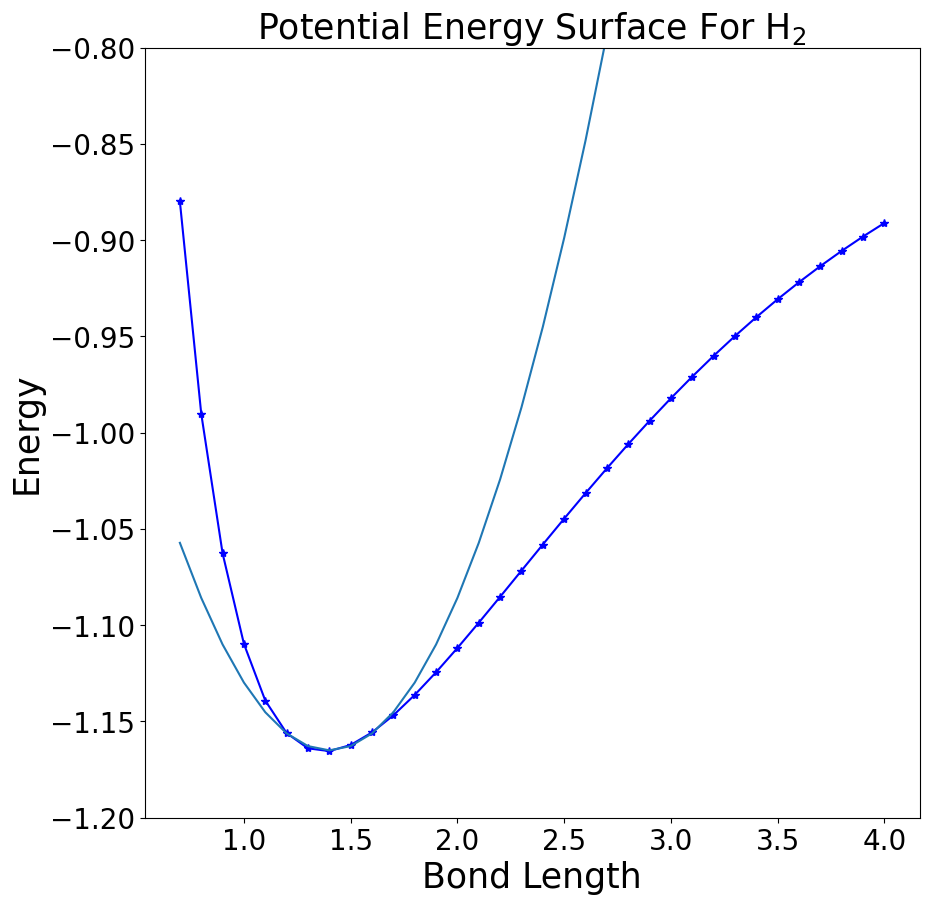

In [161]:
# Now we plot the potential energy surface

import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
plt.plot(r_list, potential_energy_list, 'b-*')
plt.plot(r_list, 0.22*(np.array(r_list)-1.4)**2 - 1.165)
plt.xlabel('Bond Length', size=25)
plt.ylabel('Energy',size=25)
plt.title('Potential Energy Surface For $\mathregular{H_2}$',size=25)
plt.xticks(fontsize= 20)
plt.yticks(fontsize= 20)
plt.ylim([-1.2, -0.8])
plt.show()

# Now, we create functions for calculating the energies and forces. The energy at each bond length, like before, is calculated using density functional theory. The force at a specific bond length is equal to the negative derivative of the potential with respect to position, evaluated at that bond length ($F(r_0)=-\frac{\partial V}{\partial r}|_{r=r_0}$, where $r_0$ is some arbitrary position). In this case, we don't have a specified function for the potential, but we can approximate the force by using the finite difference method: $F(r_0)=-\frac{E(r_0+\delta r)-E(r_0-\delta r)}{2\delta r}$, where $\delta r$ is a small, finite number by which you move away from he position $r_0$

In [59]:
def DFT_H2(r):
    mol = gto.Mole()
    mol.atom = f'''H  0 0 0; H {r} 0 0'''
    mol.basis = 'sto-3g'
    mol.unit = 'bohr'
    mol.build()

    mf = mol.KS()
    mf.xc = 'b3lyp'
    energy = mf.kernel()

    return energy

# In the code, r is what I refer to as r_0 in the above explanation, and dx is what I referred to as delta r.
def force(r, dx):
        
    force = -(DFT_H2(r+dx) - DFT_H2(r-dx))/(2*dx)
    
    return force

def harmonic_potential(k, x):
    V = 0.5*k*x**2
    
    return V
    
def force_harmonic(k,x, dx):
    
    force = -(harmonic_potential(k,x+dx) - harmonic_potential(k,x-dx))/(2*dx)
    
    return force

In [139]:
dx = 0.00001

bond_length = 1.6 #initial bond length
position_CM = 0 #initial position of center of mass
#r1 = (2*position_CM-bond_length)/2
#r2 = r1+bond_length
r1 = 0
k = 4*np.pi**2
current_positions = r1+bond_length # initial positions of the particles
current_velocities = 0 # initial velocity of each particle # This list will hold the new calculated forces
current_forces = force_harmonic(k, current_positions, dx) #force(current_positions, dx)
mass = 1 #1.0078 # mass of each particle

dt = 0.0005
time_femtoseconds = 1
time_fs_to_au = time_femtoseconds/0.0241888432658569977 # convert time from femtoseconds to au
positions_list = [current_positions]
velocities_list = [current_velocities]
forces_list = [current_forces]
energy_list = [harmonic_potential(k,current_positions)]#[DFT_H2(current_positions)]

simulation_time = np.arange(0, time_femtoseconds, dt)

tic = time.perf_counter()

for i in simulation_time[1:]:
    
    current_positions = current_positions + current_velocities*dt + (current_forces*(dt**2))/(2*mass)
    
    new_forces = force_harmonic(k, current_positions, dx) #force(current_positions, dx)
        
    current_velocities = current_velocities + ((new_forces + current_forces)*dt)/(2*mass)
        
    current_forces = new_forces
    
    positions_list.append(current_positions)
    velocities_list.append(current_velocities)
    forces_list.append(current_forces)
    energy_list.append(harmonic_potential(k,current_positions))#energy_list.append(DFT_H2(current_positions))
    

toc = time.perf_counter()
print(f"Completed simulation in {toc - tic:0.4f} seconds")

Completed simulation in 0.0263 seconds


In [ ]:
from vqe import create_noisy_sampler

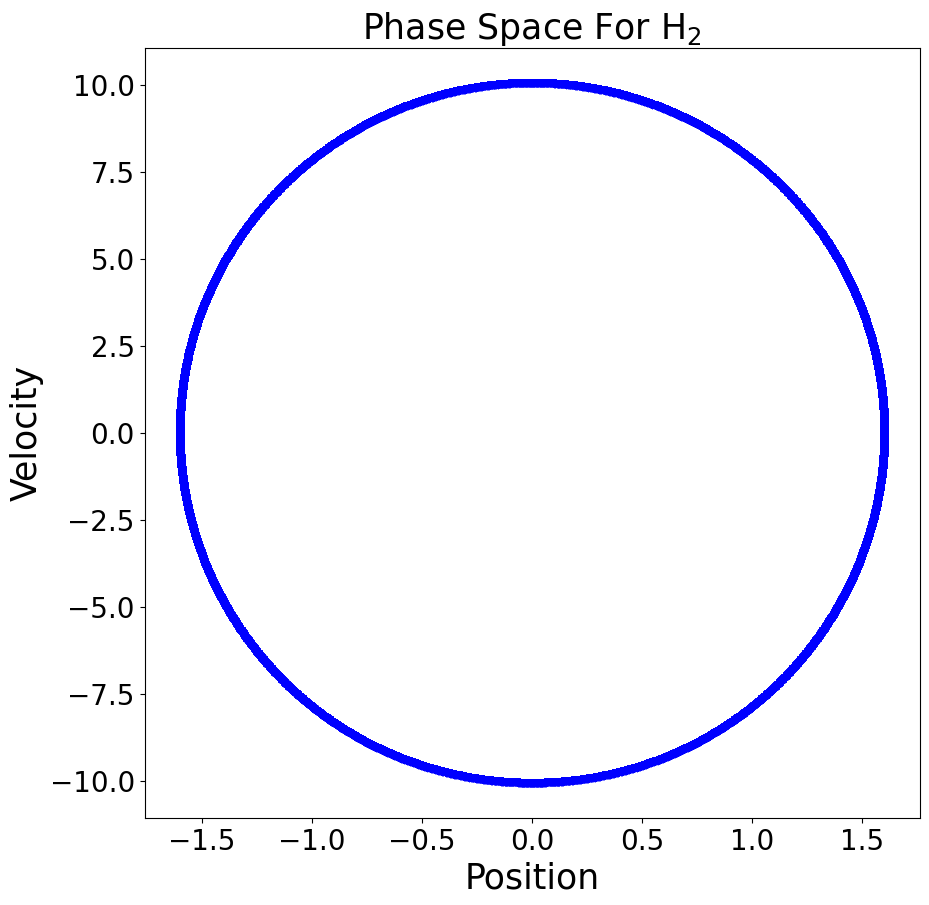

In [140]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
plt.plot(positions_list, velocities_list, 'b-*')
plt.xlabel('Position', size=25)
plt.ylabel('Velocity',size=25)
plt.title('Phase Space For $\mathregular{H_2}$',size=25)
plt.xticks(fontsize= 20)
plt.yticks(fontsize= 20)
plt.show()

In [10]:
simulation_time = np.insert(simulation_time, 0, 0.0)
print(simulation_time)

[ 0.   0.   0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  0.9  1.   1.1  1.2
  1.3  1.4  1.5  1.6  1.7  1.8  1.9  2.   2.1  2.2  2.3  2.4  2.5  2.6
  2.7  2.8  2.9  3.   3.1  3.2  3.3  3.4  3.5  3.6  3.7  3.8  3.9  4.
  4.1  4.2  4.3  4.4  4.5  4.6  4.7  4.8  4.9  5.   5.1  5.2  5.3  5.4
  5.5  5.6  5.7  5.8  5.9  6.   6.1  6.2  6.3  6.4  6.5  6.6  6.7  6.8
  6.9  7.   7.1  7.2  7.3  7.4  7.5  7.6  7.7  7.8  7.9  8.   8.1  8.2
  8.3  8.4  8.5  8.6  8.7  8.8  8.9  9.   9.1  9.2  9.3  9.4  9.5  9.6
  9.7  9.8  9.9 10.  10.1 10.2 10.3 10.4 10.5 10.6 10.7 10.8 10.9 11.
 11.1 11.2 11.3 11.4 11.5 11.6 11.7 11.8 11.9 12.  12.1 12.2 12.3 12.4
 12.5 12.6 12.7 12.8 12.9 13.  13.1 13.2 13.3 13.4 13.5 13.6 13.7 13.8
 13.9 14.  14.1 14.2 14.3 14.4 14.5 14.6 14.7 14.8 14.9 15.  15.1 15.2
 15.3 15.4 15.5 15.6 15.7 15.8 15.9 16.  16.1 16.2 16.3 16.4 16.5 16.6
 16.7 16.8 16.9 17.  17.1 17.2 17.3 17.4 17.5 17.6 17.7 17.8 17.9 18.
 18.1 18.2 18.3 18.4 18.5 18.6 18.7 18.8 18.9 19.  19.1 19.2 19.3 19.4
 19.5 19.

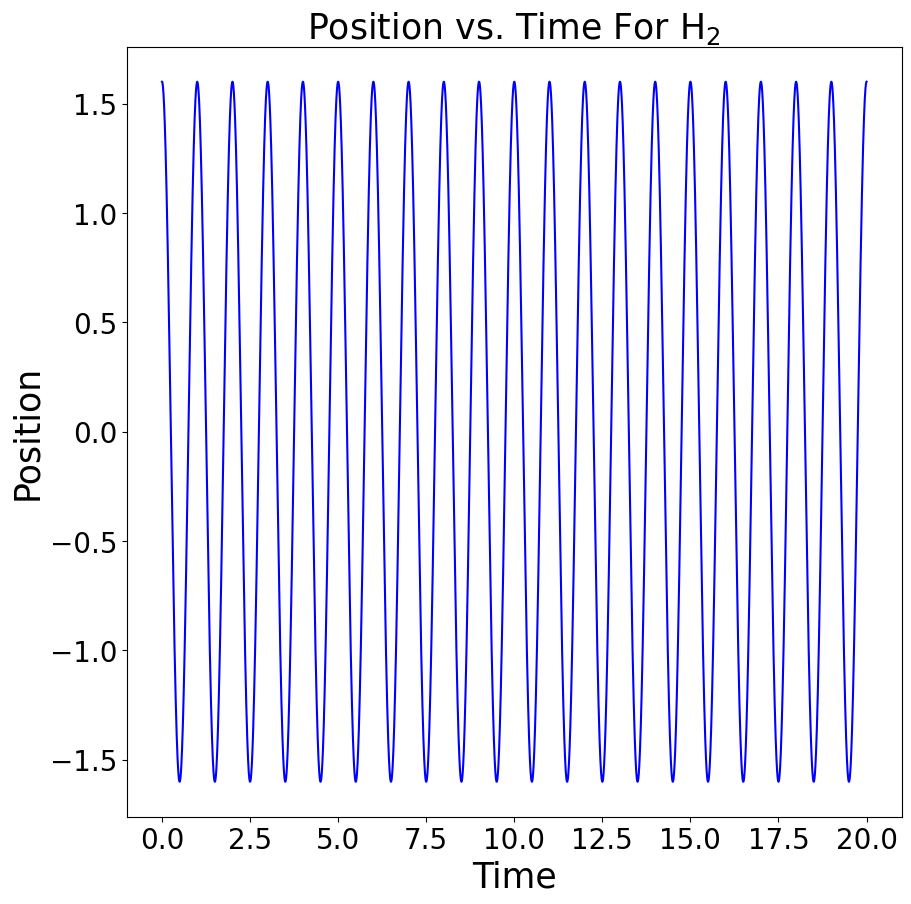

In [142]:
simulation_time = np.arange(0, time_femtoseconds, dt)
plt.figure(figsize=(10,10))
plt.plot(simulation_time, positions_list, 'b-')
# plt.plot(simulation_time, 1.6*np.cos(2*np.pi*1*simulation_time), 'r--o')
plt.xlabel('Time', size=25)
plt.ylabel('Position',size=25)
plt.title('Position vs. Time For $\mathregular{H_2}$',size=25)
plt.xticks(fontsize= 20)
plt.yticks(fontsize= 20)
plt.show()

# Fourier Transform

In [ ]:
np.pi/20

In [ ]:
T

In [ ]:
len(positions_list)

In [ ]:
print(xf)
fftshift(freq)

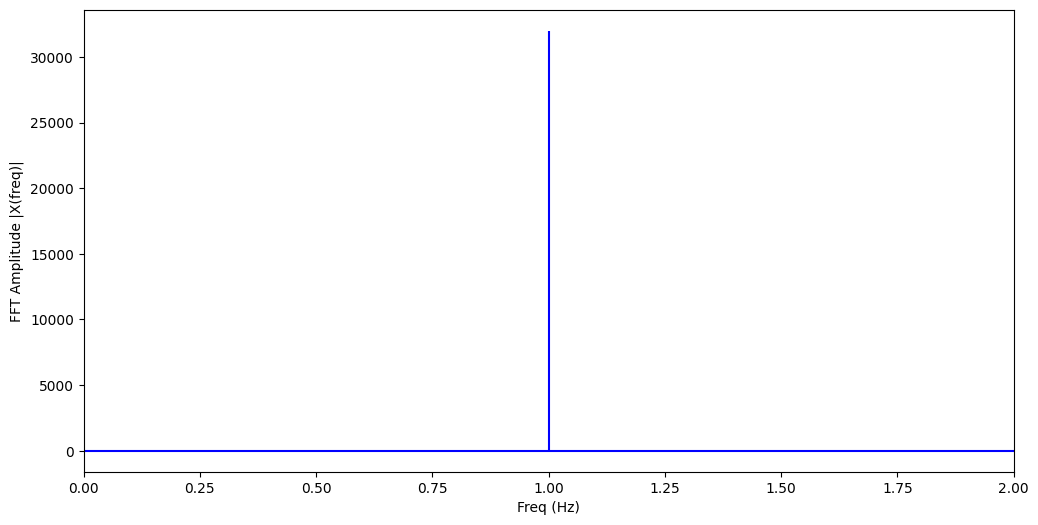

In [185]:
X = np.fft.fft(1.6*np.cos(2*np.pi*1*simulation_time))

# X = np.fft.fft(position_list)

N = len(X)
n = np.arange(N)
T = N/(1/dt)
freq = n/T

plt.figure(figsize = (12, 6))
# plt.subplot(121)


plt.stem(freq, np.abs(X), 'b', \
         markerfmt=" ", basefmt="-b")
plt.xlabel('Freq (Hz)')
plt.ylabel('FFT Amplitude |X(freq)|')
plt.xlim(0, 2)

# plt.subplot(122)
# plt.plot(ttt, np.fft.ifft(X), 'r')
# plt.xlabel('Time (s)')
# plt.ylabel('Amplitude')
# plt.tight_layout()
plt.show()

In [190]:
freq

array([0.00000e+00, 5.00000e-02, 1.00000e-01, ..., 1.99985e+03,
       1.99990e+03, 1.99995e+03])

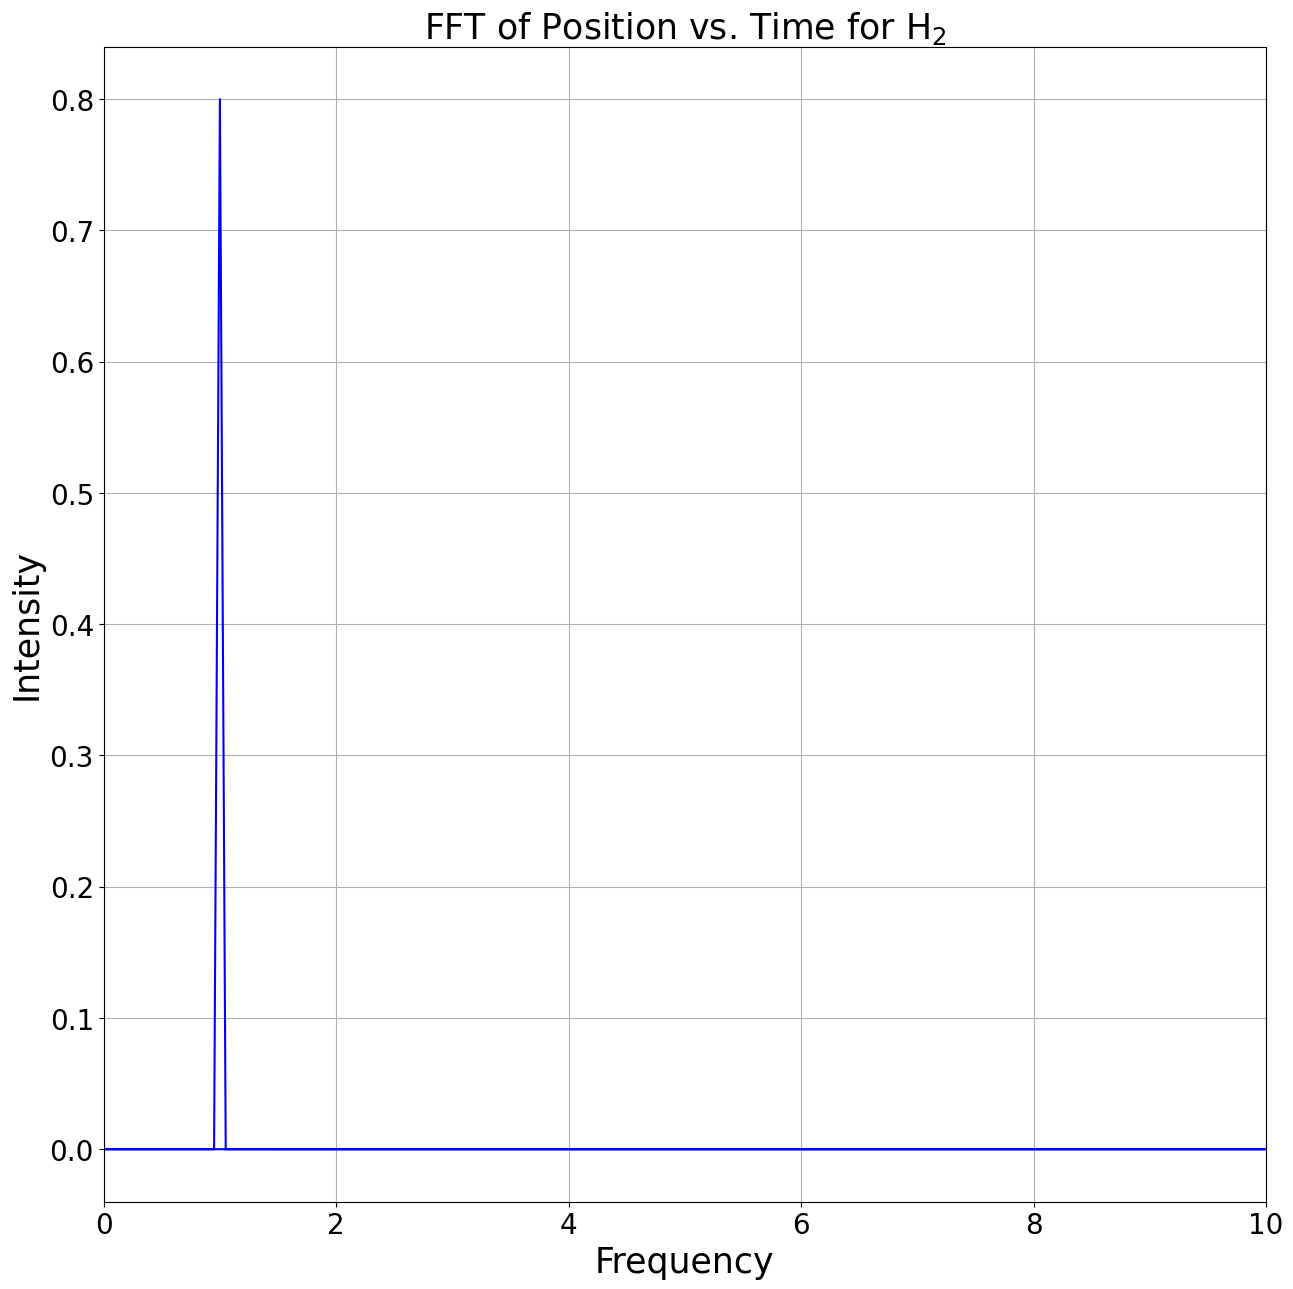

In [155]:
from scipy.fft import fft, fftfreq, fftshift
yf = np.fft.fft(positions_list)
xf = fftfreq(simulation_time.size, dt)
# xf = fftshift(xf)


N = len(yf)
n = np.arange(N)
T = N/(1/dt)
freq = n/T 

import matplotlib.pyplot as plt
plt.figure(figsize=(15,15))
plt.plot(xf, (1/len(positions_list))*np.abs(yf), 'b')
# plt.plot(fftshift(freq), (1/len(positions_list))*np.abs(yf), 'r--')
plt.xlabel('Frequency', size=25)
plt.ylabel('Intensity',size=25)
plt.title('FFT of Position vs. Time for $\mathregular{H_2}$',size=25)
plt.xticks(fontsize= 20)
plt.yticks(fontsize= 20)
plt.xlim([0,10])
plt.grid()
plt.show()

In [ ]:
print(xf)

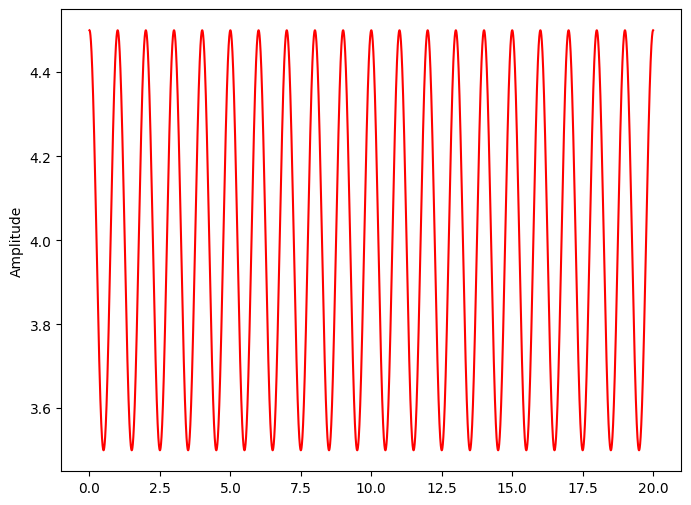

In [127]:
# sampling rate
sr = 1000
# sampling interval
ts = 1.0/sr
ttt = np.arange(0,20,ts)

freqq = 0
xxx = 3*np.cos(2*np.pi*freqq*ttt)

freqq = 0
xxx += np.cos(2*np.pi*freqq*ttt)

freqq = 1   
xxx += 0.5* np.cos(2*np.pi*freqq*ttt)

plt.figure(figsize = (8, 6))
plt.plot(ttt, xxx, 'r')
plt.ylabel('Amplitude')

plt.show()

In [ ]:
freq

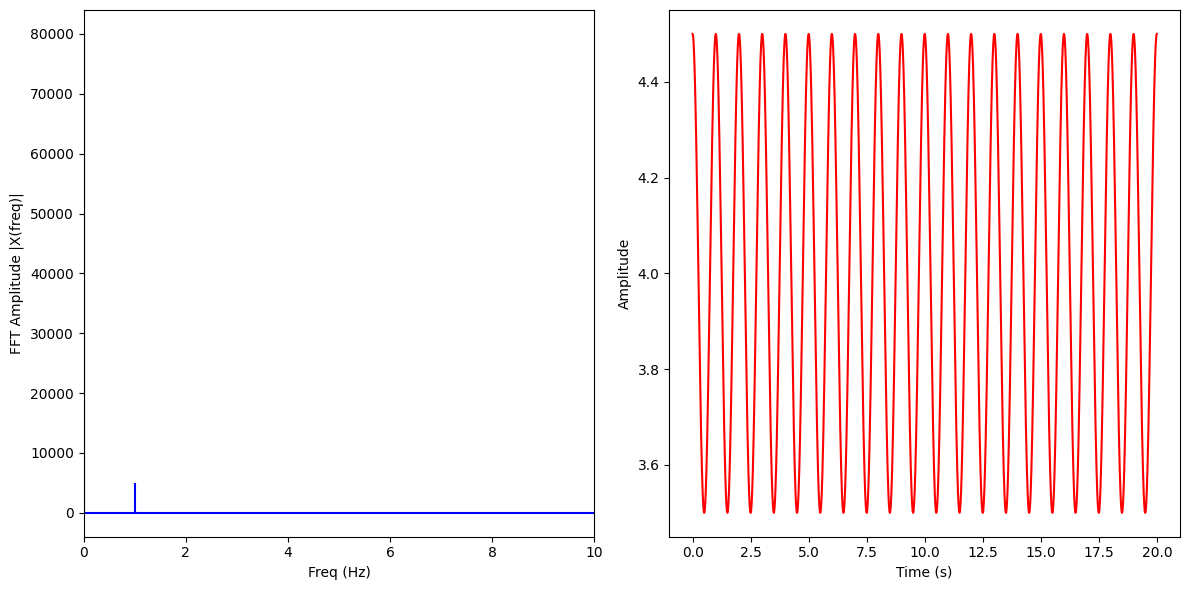

In [128]:
X = np.fft.fft(xxx)
N = len(X)
n = np.arange(N)
T = N/sr
freq = n/T

plt.figure(figsize = (12, 6))
plt.subplot(121)

plt.stem(freq, np.abs(X), 'b', \
         markerfmt=" ", basefmt="-b")
plt.xlabel('Freq (Hz)')
plt.ylabel('FFT Amplitude |X(freq)|')
plt.xlim(0, 10)

plt.subplot(122)
plt.plot(ttt, np.fft.ifft(X), 'r')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.tight_layout()
plt.show()

In [ ]:
from matplotlib import pyplot as plt
from celluloid import Camera

    
fig = plt.figure(10,10)
plt.xlim([-2, 2])
plt.ylim([-1,1])
camera = Camera(fig)
for i in range(len(positions_list)):
    plt.scatter(positions_list[i],[0]*len(current_positions), s=120, c=[1]*len(current_positions))
    plt.scatter(positionCM[i], 0, s=120, c=[2]*len(current_positions))
    text = "T = " + str(dt*i)
    plt.text(1, 0.5, text, ha='left',wrap=False)
    camera.snap()

animation = camera.animate()
animation.save('H2_gif.gif', writer = 'pillow', fps=40)

In [ ]:
f0 = force(2,0.1)

In [ ]:
print(f0)
x_step = 0.1
t_step = 0.1
x0 = 2
v0 = 0
print(f'Force0: {f0}\n', f'Position0: {x0}\n', f'Velocity0: {v0}\n\n')
m = 1.0078
x1 = x0 + v0*t_step + (f0*(t_step**2))/(2*m)
f1 = force(x1,x_step)
v1 = v0 + ((f1 + f0)*t_step)/(2*m)
print(f'Force1: {f1}\n', f'Position1: {x1}\n', f'Velocity1: {v1}\n\n')

x2 = x1 + v1*t_step + (f1*(t_step**2))/(2*m)
f2 = force(x2,x_step)
v2 = v1 + ((f2 + f1)*t_step)/(2*m)
print(f'Force2: {f2}\n', f'Position2: {x2}\n', f'Velocity2: {v2}\n\n')


In [ ]:
ts